# Task 3 — Final Experimental Analysis


In [3]:
ls -l .venv/bin/python

ls: .venv/bin/python: No such file or directory


In [4]:
from pathlib import Path
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RESULTS_DIR = PROJECT_ROOT / "results" / "module6c"
REPORTS_DIR = PROJECT_ROOT / "reports"
FIGURES_DIR = REPORTS_DIR / "figures"
TABLES_DIR = REPORTS_DIR / "tables"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

METRICS_PATH = RESULTS_DIR / "module6c_locked_test_metrics.csv"
assert METRICS_PATH.exists(), f"Metrics CSV not found: {METRICS_PATH}"
metrics = pd.read_csv(METRICS_PATH)
print("Rows:", len(metrics))
print("Timing modes:", metrics["timing_mode"].value_counts().to_dict())
print("Experiments:", sorted(metrics["experiment"].unique()))


Rows: 54
Timing modes: {'strict': 27, 'same_date': 27}
Experiments: ['A0', 'A1', 'A2', 'B0', 'B1', 'C1', 'C2', 'C3', 'C4_hl1d', 'C4_hl3d', 'C4_hl5d', 'C5_hl1d', 'C5_hl3d', 'C5_hl5d']


In [5]:
# Validate the expected evaluation structure before plotting.
assert len(metrics) == 54, f"Expected 54 evaluations, found {len(metrics)}"
assert set(metrics["timing_mode"]) == {"strict", "same_date"}
assert metrics["test_rows"].nunique() == 1 and int(metrics["test_rows"].iloc[0]) == 235
assert not metrics[["experiment", "timing_mode", "model"]].duplicated().any()
assert metrics["prediction_path"].notna().all()
display(metrics.groupby(["timing_mode"]).agg(
    evaluations=("experiment", "size"),
    test_rows=("test_rows", "min"),
    mean_mcc=("mcc", "mean"),
    median_mcc=("mcc", "median")
))


,evaluations,test_rows,mean_mcc,median_mcc
timing_mode,,,,
same_date,27,235,-0.007159,0.000000
strict,27,235,-0.016591,-0.000306


## 1. Strict-later results (primary evaluation)\n\nAll metrics below are locked-test results. The same-date track is not mixed into this comparison.

In [6]:
strict = metrics[metrics.timing_mode == "strict"].copy()
display(strict.sort_values("mcc", ascending=False)[
    ["experiment","model","test_rows","mcc","macro_f1","balanced_accuracy","accuracy","roc_auc",
     "precision_down","recall_down","f1_down","precision_up","recall_up","f1_up"]
].reset_index(drop=True))


,experiment,model,test_rows,mcc,macro_f1,balanced_accuracy,accuracy,roc_auc,precision_down,recall_down,f1_down,precision_up,recall_up,f1_up
0,C5_hl3d,mlp,235,0.118283,0.437843,0.541673,0.480851,0.503128,0.440594,0.908163,0.593333,0.727273,0.175182,0.282353
1,C5_hl5d,mlp,235,0.072386,0.383102,0.520483,0.451064,0.517727,0.427907,0.938776,0.587859,0.700000,0.102190,0.178344
2,C1,logistic_regression,235,0.065031,0.513876,0.528266,0.570213,0.539327,0.473684,0.275510,0.348387,0.601124,0.781022,0.679365
3,B0,logistic_regression,235,0.063471,0.490037,0.523946,0.578723,0.506852,0.487179,0.193878,0.277372,0.596939,0.854015,0.702703
4,C5_hl1d,mlp,235,0.035643,0.455775,0.515492,0.472340,0.474229,0.426966,0.775510,0.550725,0.614035,0.255474,0.360825
5,B0,mlp,235,0.033454,0.481169,0.512997,0.565957,0.492403,0.452381,0.193878,0.271429,0.590674,0.832117,0.690909
6,A1,logistic_regression,235,0.027152,0.513566,0.513556,0.527660,0.513556,0.432990,0.428571,0.430769,0.594203,0.598540,0.596364
7,A2,mlp,235,0.026153,0.505691,0.512178,0.544681,0.495978,0.436620,0.316327,0.366864,0.591463,0.708029,0.644518
8,C1,mlp,235,0.022289,0.504868,0.511284,0.506383,0.541040,0.427419,0.540816,0.477477,0.594595,0.481752,0.532258
9,B1,mlp,235,0.014404,0.475266,0.505698,0.557447,0.506033,0.431818,0.193878,0.267606,0.586387,0.817518,0.682927


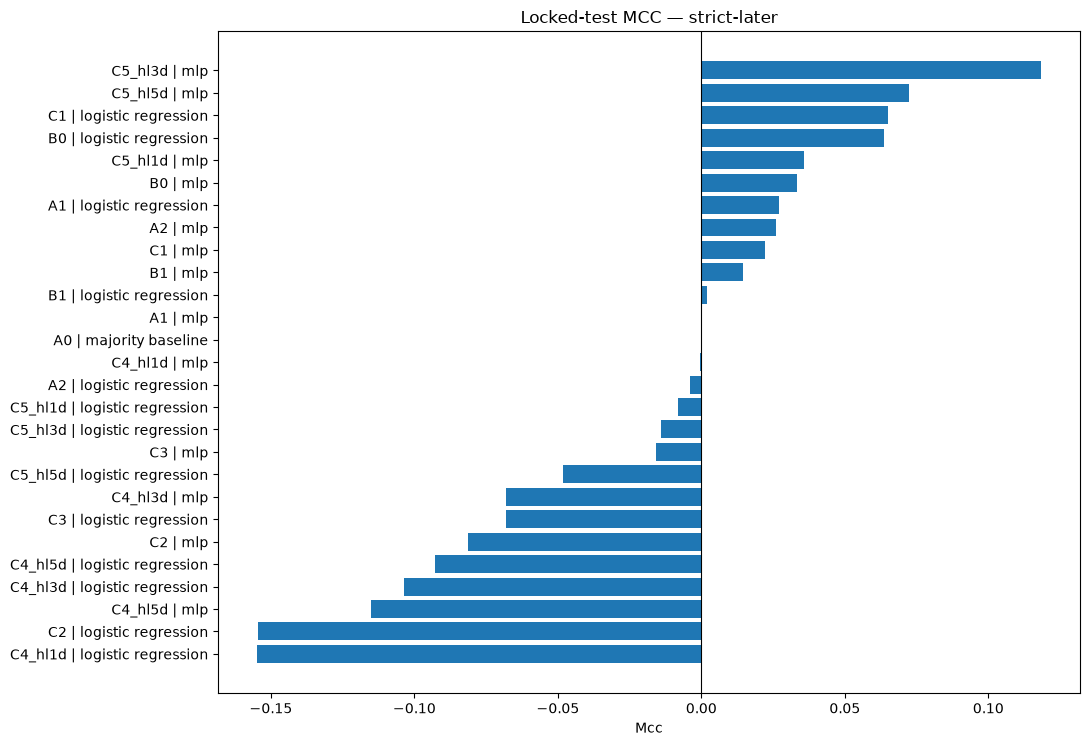

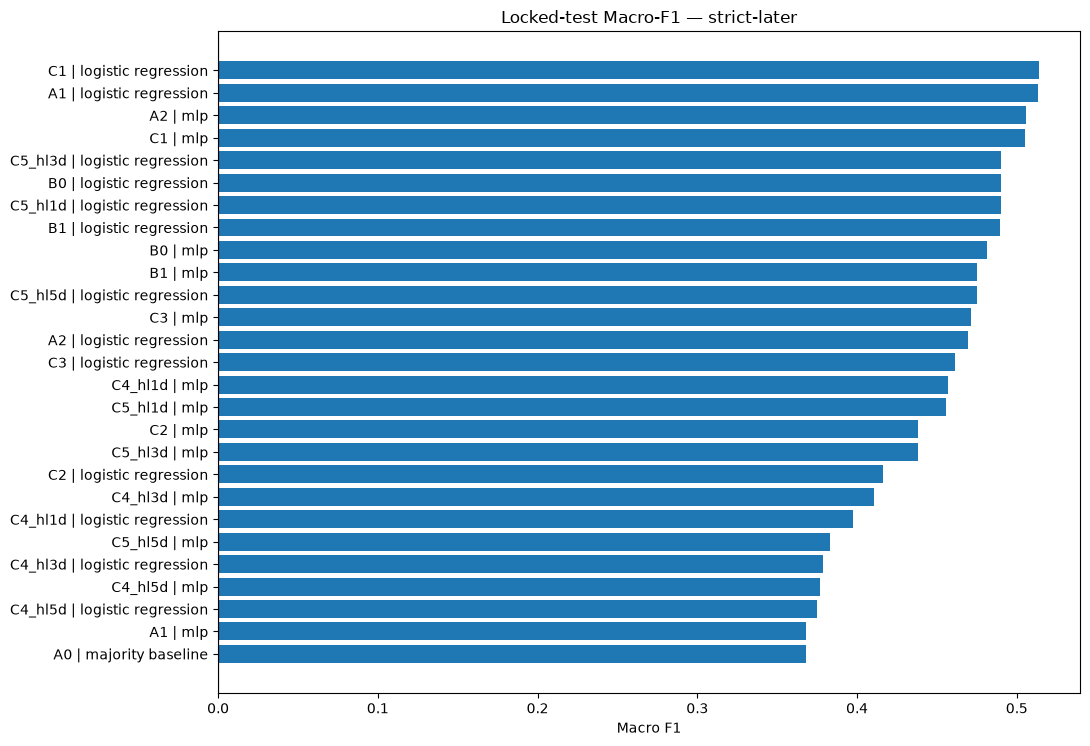

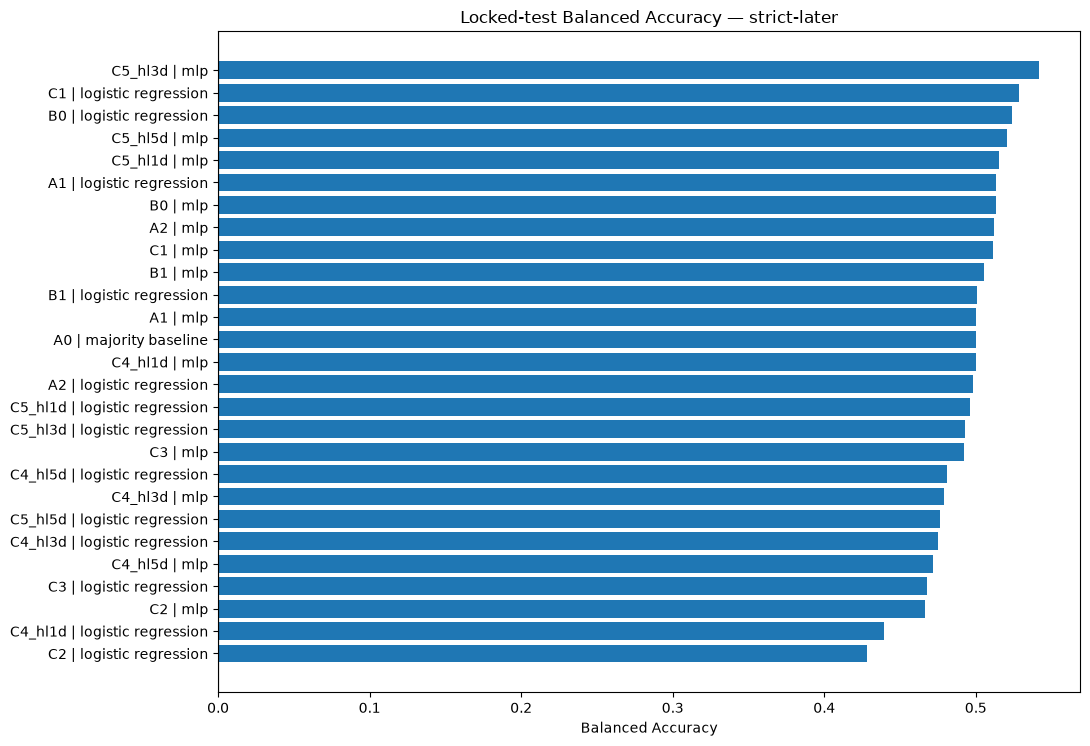

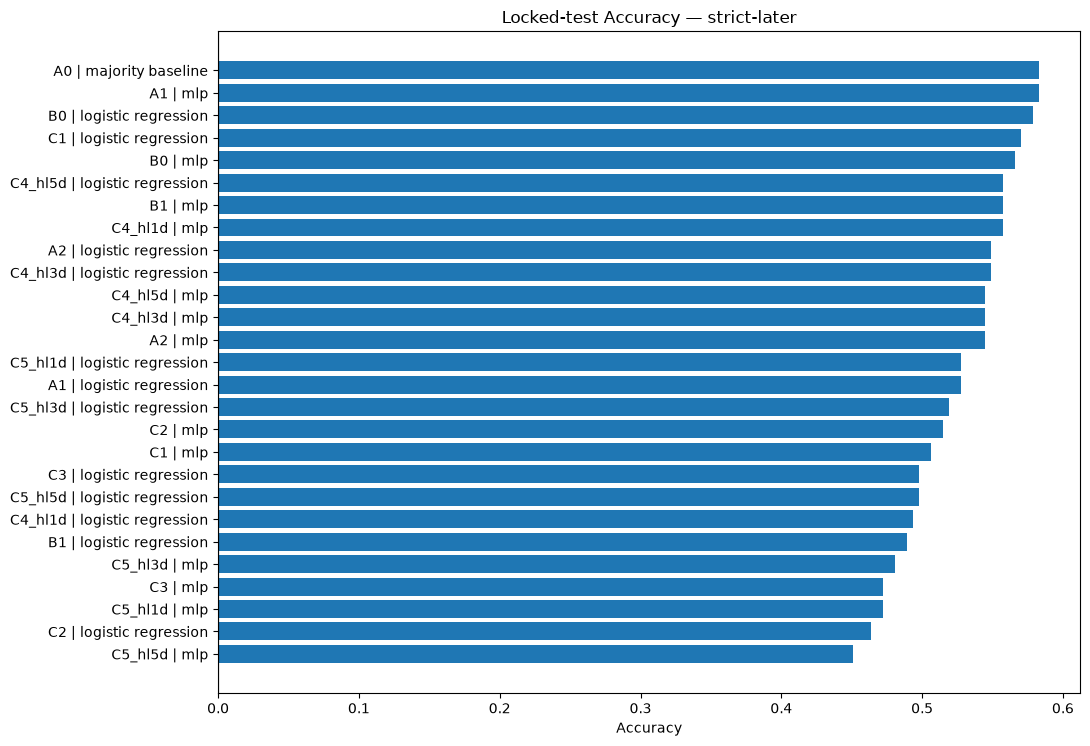

In [7]:
def plot_metric(data, metric, title, filename):
    d = data.sort_values(metric).copy()
    labels = [f"{r.experiment} | {r.model.replace('_',' ')}" for r in d.itertuples()]
    fig, ax = plt.subplots(figsize=(11, max(6, 0.28*len(d))))
    ax.barh(labels, d[metric])
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_xlabel(metric.replace("_"," ").title())
    ax.set_title(title)
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / filename, dpi=220, bbox_inches="tight")
    plt.show()

plot_metric(strict, "mcc", "Locked-test MCC — strict-later", "strict_later_mcc.png")
plot_metric(strict, "macro_f1", "Locked-test Macro-F1 — strict-later", "strict_later_macro_f1.png")
plot_metric(strict, "balanced_accuracy", "Locked-test Balanced Accuracy — strict-later", "strict_later_balanced_accuracy.png")
plot_metric(strict, "accuracy", "Locked-test Accuracy — strict-later", "strict_later_accuracy.png")


## 2. Same-date sensitivity results\n\nThis is a separate sensitivity analysis. Because article timestamps are date-only, same-date alignment is not evidence of verified intraday availability.

,experiment,model,test_rows,mcc,macro_f1,balanced_accuracy,accuracy,roc_auc
0,C1,mlp,235,0.134953,0.556384,0.561783,0.595745,0.554670
1,C3,mlp,235,0.056912,0.526557,0.528825,0.531915,0.559809
2,B0,logistic_regression,235,0.054512,0.500116,0.522456,0.570213,0.518919
3,C1,logistic_regression,235,0.046765,0.517436,0.523685,0.519149,0.537986
4,C4_hl1d,logistic_regression,235,0.033393,0.492293,0.516312,0.493617,0.498734
5,C5_hl1d,mlp,235,0.030923,0.511702,0.515679,0.514894,0.515865
6,C5_hl5d,mlp,235,0.030743,0.501001,0.513668,0.553191,0.494712
7,A1,logistic_regression,235,0.027152,0.513566,0.513556,0.527660,0.513556
8,A2,mlp,235,0.026153,0.505691,0.512178,0.544681,0.495978
9,B1,logistic_regression,235,0.023224,0.503073,0.510725,0.544681,0.486221


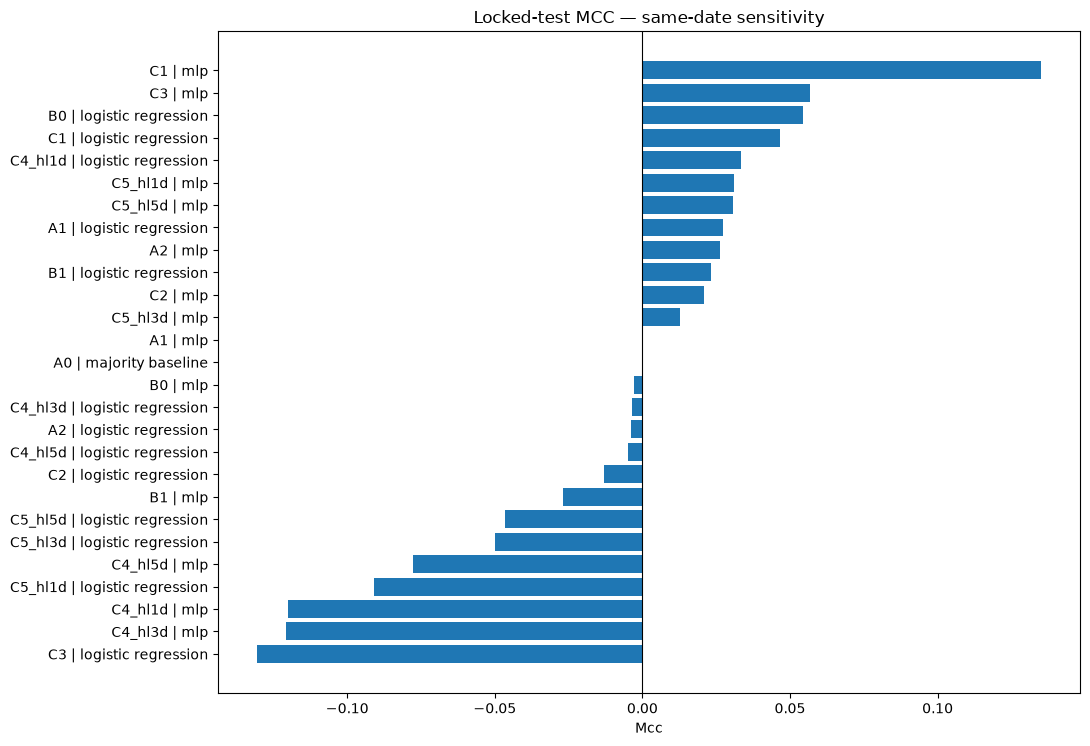

In [8]:
same_date = metrics[metrics.timing_mode == "same_date"].copy()
display(same_date.sort_values("mcc", ascending=False)[
    ["experiment","model","test_rows","mcc","macro_f1","balanced_accuracy","accuracy","roc_auc"]
].reset_index(drop=True))
plot_metric(same_date, "mcc", "Locked-test MCC — same-date sensitivity", "same_date_mcc.png")


## 3. Ablation summary\n\nExperiment IDs follow the project's experiment matrix. Keep the classifier visible: comparing different classifier families does not isolate the representation effect.

In [9]:
ablation = strict.pivot_table(index="experiment", columns="model",
    values=["mcc","macro_f1","balanced_accuracy","accuracy"], aggfunc="first")
display(ablation)
ablation.to_csv(TABLES_DIR / "strict_later_ablation_metrics.csv")


accuracy                              \
model      logistic_regression majority_baseline       mlp   
experiment                                                   
A0                         NaN          0.582979       NaN   
A1                    0.527660               NaN  0.582979   
A2                    0.548936               NaN  0.544681   
B0                    0.578723               NaN  0.565957   
B1                    0.489362               NaN  0.557447   
C1                    0.570213               NaN  0.506383   
C2                    0.463830               NaN  0.514894   
C3                    0.497872               NaN  0.472340   
C4_hl1d               0.493617               NaN  0.557447   
C4_hl3d               0.548936               NaN  0.544681   
C4_hl5d               0.557447               NaN  0.544681   
C5_hl1d               0.527660               NaN  0.472340   
C5_hl3d               0.519149               NaN  0.480851   
C5_hl5d               0.497872               NaN  0.451064   

             balanced_accuracy                              \
model      logistic_regression majority_baseline       mlp   
experiment                                                   
A0                         NaN               0.5       NaN   
A1                    0.513556               NaN  0.500000   
A2                    0.498399               NaN  0.512178   
B0                    0.523946               NaN  0.512997   
B1                    0.501043               NaN  0.505698   
C1                    0.528266               NaN  0.511284   
C2                    0.428311               NaN  0.466297   
C3                    0.467675               NaN  0.492254   
C4_hl1d               0.439334               NaN  0.499888   
C4_hl3d               0.475160               NaN  0.478773   
C4_hl5d               0.481007               NaN  0.471511   
C5_hl1d               0.496127               NaN  0.515492   
C5_hl3d               0.493185               NaN  0.541673   
C5_hl5d               0.476389               NaN  0.520483   

                      macro_f1                              \
model      logistic_regression majority_baseline       mlp   
experiment                                                   
A0                         NaN           0.36828       NaN   
A1                    0.513566               NaN  0.368280   
A2                    0.469368               NaN  0.505691   
B0                    0.490037               NaN  0.481169   
B1                    0.489278               NaN  0.475266   
C1                    0.513876               NaN  0.504868   
C2                    0.416391               NaN  0.437846   
C3                    0.461595               NaN  0.471565   
C4_hl1d               0.397163               NaN  0.457178   
C4_hl3d               0.378741               NaN  0.410862   
C4_hl5d               0.374872               NaN  0.376689   
C5_hl1d               0.489820               NaN  0.455775   
C5_hl3d               0.490199               NaN  0.437843   
C5_hl5d               0.475049               NaN  0.383102   

                           mcc                              
model      logistic_regression majority_baseline       mlp  
experiment                                                  
A0                         NaN               0.0       NaN  
A1                    0.027152               NaN  0.000000  
A2                   -0.003980               NaN  0.026153  
B0                    0.063471               NaN  0.033454  
B1                    0.002077               NaN  0.014404  
C1                    0.065031               NaN  0.022289  
C2                   -0.154585               NaN -0.081209  
C3                   -0.068146               NaN -0.015748  
C4_hl1d              -0.154726               NaN -0.000306  
C4_hl3d              -0.103489               NaN -0.067893  
C4_hl5d              -0.092791               NaN -0.114929  
C5_

## 4. Exponential-decay sensitivity

,experiment,model,half_life_trading_days,mcc,macro_f1,balanced_accuracy,accuracy
15,C4_hl1d,logistic_regression,1,-0.154726,0.397163,0.439334,0.493617
17,C4_hl3d,logistic_regression,3,-0.103489,0.378741,0.475160,0.548936
19,C4_hl5d,logistic_regression,5,-0.092791,0.374872,0.481007,0.557447
16,C4_hl1d,mlp,1,-0.000306,0.457178,0.499888,0.557447
18,C4_hl3d,mlp,3,-0.067893,0.410862,0.478773,0.544681
20,C4_hl5d,mlp,5,-0.114929,0.376689,0.471511,0.544681
21,C5_hl1d,logistic_regression,1,-0.008254,0.489820,0.496127,0.527660
23,C5_hl3d,logistic_regression,3,-0.014141,0.490199,0.493185,0.519149
25,C5_hl5d,logistic_regression,5,-0.048108,0.475049,0.476389,0.497872
22,C5_hl1d,mlp,1,0.035643,0.455775,0.515492,0.472340


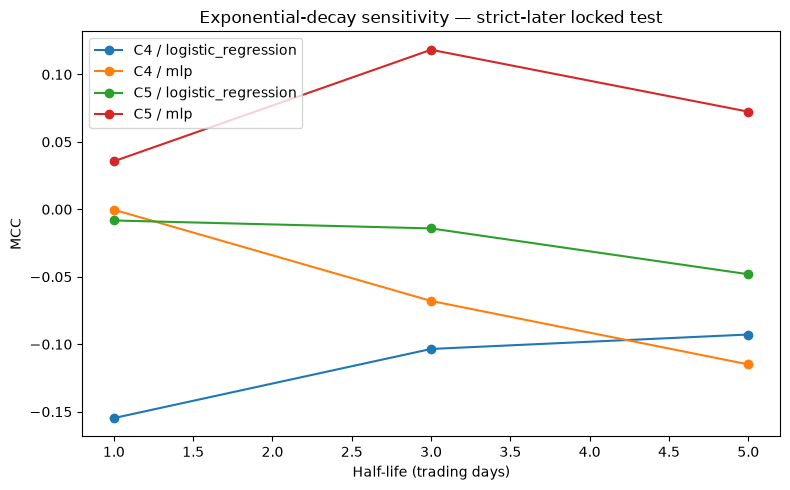

In [11]:

decay = strict[strict["experiment"].str.match(r"C[45]_hl")].copy()

decay["half_life_trading_days"] = (
    decay["experiment"]
    .str.extract(r"hl(\d+)d")
    .astype(int)
)

decay["representation_family"] = (
    decay["experiment"]
    .str.extract(r"^(C[45])")
)

display(
    decay.sort_values(
        ["representation_family", "model", "half_life_trading_days"]
    )[
        [
            "experiment",
            "model",
            "half_life_trading_days",
            "mcc",
            "macro_f1",
            "balanced_accuracy",
            "accuracy"
        ]
    ]
)

fig, ax = plt.subplots(figsize=(8, 5))

for (family, model), group in decay.groupby(
    ["representation_family", "model"]
):
    group = group.sort_values("half_life_trading_days")
    ax.plot(
        group["half_life_trading_days"],
        group["mcc"],
        marker="o",
        label=f"{family} / {model}"
    )

ax.set_xlabel("Half-life (trading days)")
ax.set_ylabel("MCC")
ax.set_title("Exponential-decay sensitivity — strict-later locked test")
ax.legend()
fig.tight_layout()

fig.savefig(
    FIGURES_DIR / "decay_half_life_mcc.png",
    dpi=220,
    bbox_inches="tight"
)

plt.show()


## 5. Prediction-level error analysis\n\nThe notebook reads the prediction CSVs referenced by the metrics table. It does not infer dates or outcomes from filenames.

In [12]:
def load_prediction(row):
    path = PROJECT_ROOT / row.prediction_path
    assert path.exists(), f"Prediction file missing: {path}"
    pred = pd.read_csv(path)
    assert len(pred) == int(row.test_rows), f"Unexpected row count in {path}"
    assert {"Date","target_date","target_direction","prediction","score"}.issubset(pred.columns)
    return pred

# Best strict-later model by MCC, and best same-date model by MCC.
best_rows = pd.concat([
    strict.loc[[strict.mcc.idxmax()]],
    same_date.loc[[same_date.mcc.idxmax()]]
], ignore_index=True)
error_frames = []
for row in best_rows.itertuples(index=False):
    p = load_prediction(row)
    p["correct"] = p.target_direction.astype(bool) == p.prediction.astype(bool)
    p["experiment"] = row.experiment
    p["timing_mode"] = row.timing_mode
    p["model"] = row.model
    error_frames.append(p)
best_predictions = pd.concat(error_frames, ignore_index=True)
display(best_predictions.groupby(["timing_mode","correct"]).size().rename("rows").reset_index())


,timing_mode,correct,rows
0,same_date,False,95
1,same_date,True,140
2,strict,False,122
3,strict,True,113


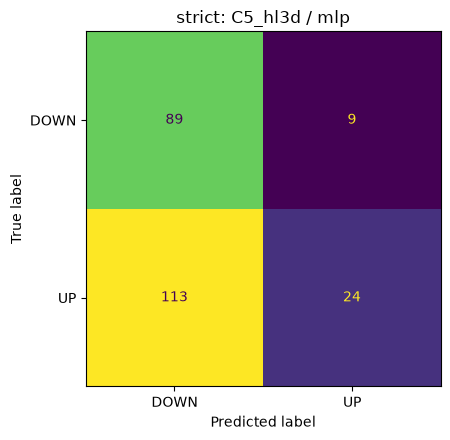


strict — C5_hl3d / mlp
Confusion matrix [DOWN, UP]:
[[ 89   9]
 [113  24]]
Misclassified rows: 122


,Date,target_date,target_direction,prediction,score
0,2025-08-29,2025-09-01,True,False,0.315335
1,2025-09-01,2025-09-02,False,True,0.503078
2,2025-09-02,2025-09-03,True,False,0.465363
3,2025-09-03,2025-09-04,True,False,0.413850
6,2025-09-09,2025-09-10,False,True,0.541900
7,2025-09-10,2025-09-11,True,False,0.450291
9,2025-09-12,2025-09-15,True,False,0.491250
10,2025-09-15,2025-09-16,False,True,0.561760
19,2025-09-26,2025-09-29,False,True,0.561472
26,2025-10-07,2025-10-08,True,False,0.331107


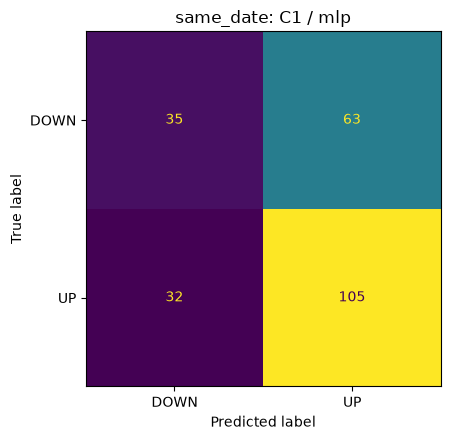


same_date — C1 / mlp
Confusion matrix [DOWN, UP]:
[[ 35  63]
 [ 32 105]]
Misclassified rows: 95


,Date,target_date,target_direction,prediction,score
0,2025-08-29,2025-09-01,True,False,0.355095
1,2025-09-01,2025-09-02,False,True,0.545788
2,2025-09-02,2025-09-03,True,False,0.351092
3,2025-09-03,2025-09-04,True,False,0.425250
7,2025-09-10,2025-09-11,True,False,0.467509
12,2025-09-17,2025-09-18,True,False,0.490420
16,2025-09-23,2025-09-24,True,False,0.481457
18,2025-09-25,2025-09-26,True,False,0.406368
20,2025-09-29,2025-09-30,True,False,0.317126
22,2025-10-01,2025-10-02,False,True,0.551846


In [13]:
for row in best_rows.itertuples(index=False):
    p = load_prediction(row)
    y_true = p.target_direction.astype(bool)
    y_pred = p.prediction.astype(bool)
    cm = confusion_matrix(y_true, y_pred, labels=[False, True])
    fig, ax = plt.subplots(figsize=(5.5,4.5))
    ConfusionMatrixDisplay(cm, display_labels=["DOWN","UP"]).plot(ax=ax, colorbar=False)
    ax.set_title(f"{row.timing_mode}: {row.experiment} / {row.model}")
    fig.tight_layout()
    safe = f"{row.timing_mode}_best_confusion_matrix.png"
    fig.savefig(FIGURES_DIR / safe, dpi=220, bbox_inches="tight")
    plt.show()
    errors = p.loc[y_true != y_pred, ["Date","target_date","target_direction","prediction","score"]]
    errors.to_csv(TABLES_DIR / f"{row.timing_mode}_best_model_errors.csv", index=False)
    print(f"\n{row.timing_mode} — {row.experiment} / {row.model}")
    print("Confusion matrix [DOWN, UP]:")
    print(cm)
    print("Misclassified rows:", len(errors))
    display(errors.head(15))


## 6. Export complete result tables

In [14]:
metrics.to_csv(TABLES_DIR / "module6c_all_54_locked_test_metrics.csv", index=False)
strict.to_csv(TABLES_DIR / "module6c_strict_later_metrics.csv", index=False)
same_date.to_csv(TABLES_DIR / "module6c_same_date_metrics.csv", index=False)
print("Saved tables to:", TABLES_DIR.resolve())
print("Saved figures to:", FIGURES_DIR.resolve())


Saved tables to: /Users/lommy/nlp-geopolitical-news-usd-prediction/hana-work/reports/tables
Saved figures to: /Users/lommy/nlp-geopolitical-news-usd-prediction/hana-work/reports/figures
